# Which GPU work did PyTorch launch?

`capture` profiles one warmed-up training step and returns `prof.events()`.
`rows` holds every event once, with `launcher_id` pointing at the event that
launched it (a CPU op's `cpu_parent`, or a kernel's CUDA launch call), so
`aten::mm -> cudaLaunchKernel -> kernel` is a chain of `launcher_id` links.

Module hooks record `forward::<module_fqn>` scopes, and autograd node hooks restore
the same path as `backward::<module_fqn>` during backward. A kernel belongs to its
nearest module scope; with none it is `<unattributed>`. `aggregate_kernels` does the
attribution and raises if a kernel is owned by a module but never reaches the root scope.

1. Setup and capture
2. Every kernel with its module
3. Time per module
4. Timeline
5. FLOPs check
6. Appendix: what each id is, and one kernel's launch chain

### What `capture` does

`capture` runs on a GPU worker: a plain warmup loop, then a measured loop over the same training step. Every input is passed explicitly in the call below.

1. Build the model, optimizer and random tokens.
2. Run `warmup_steps` plain steps, then synchronize.
3. Run `profile_steps` steps, each under the instruments `capture`'s switches turn on, and each ending in a synchronize. Both loops run forward and loss under `autocast`. Each phase of the step is wrapped in `record_function`, so it shows up by name: `train::zero_grad`, `train::forward`, `train::loss`, `train::backward`, `train::optimizer_step`.
4. Return each step's readings (profiler `events`, memory peaks, allocator `snapshot` and `wall_clock_phase_times`) under `steps`, each device's `total_memory` and the `size_estimation` of the model and the optimizer state.

`capture` takes one keyword switch per instrument: `profile`, `module_scopes`, `peak` (peak allocated and reserved per step), `trace` (each step's allocator trace, behind the memory plot) and `wall_clock` (each phase of the step timed between synchronizes). `capture_profiler_events` and `capture_memory`, in `profile_events.py`, are the context managers behind `kernel_events` and `peak`/`trace`; each does nothing when its switch is off.

**`record_function(name)`** adds a `user_annotation` event with that name. It is a label we add, not an operation PyTorch ran. Anything that starts and ends inside its time span becomes its child, so parent and child are decided by timestamps.

**`module_scopes(model)`** does the same per module: `forward::<module>` around each module's forward call, and `backward::<module>` around the backward work it owns. Later, a kernel is assigned to the module whose scope contains its launch.

A typical start of the events, in order, with start and end times in microseconds (illustrative values; the ids are from a real capture). `device_type` says where an event executed, CPU or GPU. Each indented row is a child of the row above it that is one level less indented. Annotations are ours, the rest is PyTorch:

```
                                       device_type      activity_type                     correlation_id  linked_correlation_id  start   end
train::zero_grad                       DeviceType.CPU   user_annotation            1 (frontend, PyTorch)                      0      0    40
  Optimizer.zero_grad#AdamW.zero_grad  DeviceType.CPU   user_annotation (PyTorch)  2 (frontend, PyTorch)                      0      5    35
train::forward                         DeviceType.CPU   user_annotation            3 (frontend, PyTorch)                      0     40  4200
  forward::model                       DeviceType.CPU   user_annotation            4 (frontend, PyTorch)                      0     45  4190
    forward::model.embedding           DeviceType.CPU   user_annotation            5 (frontend, PyTorch)                      0     50   300
      aten::index                      DeviceType.CPU   cpu_op                     6 (frontend, PyTorch)                      0     60   290
        cudaLaunchKernel               DeviceType.CPU   cuda_runtime                 11 (backend, CUPTI)  6 (frontend, PyTorch)    100   120
          vectorized_gather_kernel     DeviceType.CUDA  kernel (on the GPU)          11 (backend, CUPTI)  6 (frontend, PyTorch)    130   142
```

**Linking.** Parent and child among CPU events come from the timestamps, as above. A GPU event has no CPU parent in the trace, so `link_events` finds its launcher with correlation ids.

**CUDA** is NVIDIA's platform for running programs on its GPUs. It has a CPU side and a GPU side:

- On the CPU, the CUDA runtime library (`cuda_runtime` events, e.g. `cudaLaunchKernel`, `cudaMemcpyAsync`) and the lower-level driver it calls into (`cuda_driver`). These are ordinary CPU function calls that queue work for the GPU and return immediately.
- On the GPU, the work that was queued: `kernel`, `gpu_memcpy`, `gpu_memset`.

The `correlation_id` column holds ids from two separate namespaces, and the same number can appear in both. The boundary is who recorded the event, not CPU versus GPU:

- **Frontend:** events PyTorch's own profiler records for the operations your Python code calls: `cpu_op` and `user_annotation`. PyTorch numbers them with its own counter (1 to 6 above).
- **Backend:** every event of the CUDA layer, recorded by CUPTI, NVIDIA's profiling library (the CUDA Profiling Tools Interface). That is both the CPU-side CUDA calls (`cuda_runtime`, `cuda_driver`) and the GPU work they launch (`kernel`, `gpu_memcpy`, `gpu_memset`). CUPTI numbers them with its own counter (11 above), and a kernel gets the same id as the call that launched it.

So `device_type` is not the namespace boundary. `cudaLaunchKernel` has `DeviceType.CPU` because it executes on the CPU, yet its `correlation_id` is a backend id. `DeviceType.CUDA` marks only the GPU-side events, so it is not a name for the whole backend namespace. The namespace follows `activity_type`.

`linked_correlation_id` crosses between them. On a launch call or GPU event it holds the frontend `correlation_id` of the op that issued the launch (6, `aten::index`).

`link_events` keeps one lookup per namespace, so an id is only ever compared with ids of its own kind:

1. A kernel's backend `correlation_id` is looked up among the launch calls, so it is matched to the `cuda_runtime` call that launched it (11).
2. The launch call's `linked_correlation_id` is looked up among the frontend ids, so the call is matched to the op that issued it (6).

Each match sets `launcher_id` to the matched event's row. Following `launcher_id` from the kernel gives `kernel -> cudaLaunchKernel -> aten::index -> forward::model.embedding -> ...`, which is how a kernel finds its module scope. If a match is missing or ambiguous, `launcher_id` stays empty and the kernel is unattributed. See "What each id is" in the appendix.

In [21]:
import modal
import torch

import main
from profile_events import (
    aggregate_kernels,
    display_steps,
    events_to_rows,
    launch_chain,
)
from gpus.peaks import gpu_specs
from step_report import build_report

app = modal.App("profile-events")
# The worker image, so its torch is the uv.lock version that unpickles the events locally.
# The container imports profile_events for module_scopes, and fast_transformer to build a FastTransformer.
image = main.worker_image.add_local_python_source("profile_events", "fast_transformer")


# No gpu here: the caller picks it with capture.with_options(gpu=...).
@app.function(image=image, timeout=600)
def capture(
    declaration, *, batch_size, warmup_steps, profile_steps, autocast,
    kernel_events, module_scopes, peak, trace, wall_clock,
) -> dict:
    """Return the measured loop's results after a plain warmup loop over the same model and optimizer.

    It needs a GPU, so call it as capture.with_options(gpu="L4").remote(...), or any other GPU type.
    Each step trains on the same batch_size random sequences of the model's sequence_length.
    autocast is the dtype forward and loss run in, or None; warmup and the measured loop share it,
    so warmup prepares the same kernels. The switches pick the instruments around every measured
    step: kernel_events (torch profiler), module_scopes (forward::/backward:: annotations), peak (peak
    allocated and reserved bytes), trace (the allocator trace) and wall_clock (each phase
    of the step timed between synchronizes: "wall_clock_phase_times" holds each phase's duration in
    ms and "wall_clock_phase_spans" its (start, end) in us on the unix clock, both keyed by phase
    name). Every measured step ends in a synchronize. The result has "steps" ({step: {"events",
    "trace_start_us", and capture_memory's readings}}), "size_estimation" ({"model", "optimizer"}, each with
    parameters and bytes), "persistent_memory" (bytes of weights, gradients and optimizer state),
    "device_vram" (total bytes on the GPU), "step_flops" (FlopCounterMode's algorithmic estimate, in FLOPs, for
    one training step of the batch), "precision" (str of the autocast dtype, else of the model's dtype)
    and "gpu" (torch.cuda.get_device_name()). Each step also has "step_ms", the wall time of the
    step, instruments included. The last five are one-off quantities, measured once per call.
    It also returns what it ran with, for step_report.build_report: "parameters" (its own
    arguments), "model_class" and "model_parameters" (the declaration's class name and fields),
    "optimizer" (its class name) and "compile" (whether the model was compiled).
    """
    import dataclasses
    import time
    from contextlib import contextmanager, nullcontext

    import profile_events
    import torch
    from torch import nn
    from torch.profiler import record_function
    from torch.utils.flop_counter import FlopCounterMode

    torch.manual_seed(0)
    network = declaration.build()
    model = torch.compile(network)  # or model = network, to train eagerly
    # model = network
    tokens = torch.randint(
        0, declaration.vocab_size, (batch_size, declaration.sequence_length),
        generator=torch.Generator().manual_seed(0)).to(declaration.device)

    model.train()
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.02, fused=True)
    # Next-token prediction: each position predicts the following input token.
    targets = tokens[:, 1:].reshape(-1)

    phase_spans = {}  # name: (start, end) of the latest step, in us on the unix clock

    def size_of(tensors):
        tensors = list(tensors)
        return {"parameters": sum(t.numel() for t in tensors),
                "bytes": sum(t.numel() * t.element_size() for t in tensors)}

    @contextmanager
    def phase(name):
        """Wrap one phase of the step in train::<name>; with wall_clock, time it between synchronizes."""
        with record_function(f"train::{name}"):
            if not wall_clock:
                yield
                return
            torch.cuda.synchronize()
            start = time.time_ns() / 1e3
            yield
            torch.cuda.synchronize()
            phase_spans[name] = start, time.time_ns() / 1e3

    def train_step(module=model):
        with phase("zero_grad"):
            optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=autocast) if autocast else nullcontext():  # backward and the optimizer run outside autocast
            with phase("forward"):
                logits = module(tokens)
            with phase("loss"):
                loss = nn.functional.cross_entropy(
                    logits[:, :-1, :].reshape(-1, logits.shape[-1]), targets
                )
        with phase("backward"):
            loss.backward()
        with phase("optimizer_step"):
            optimizer.step()

    # One training step of the uncompiled network under FlopCounterMode, before warmup: an algorithmic
    # estimate of the FLOPs of a step of this model and batch, from the op shapes, not a hardware
    # counter. It counts forward and backward matmuls and attention; the loss, the optimizer and other
    # elementwise work are not counted. It is also an extra step of training, which no measurement sees.
    with FlopCounterMode(display=False) as flop_counter:
        train_step(network)
    step_flops = flop_counter.get_total_flops()

    for _ in range(warmup_steps):
        train_step()
    # Finish warmup first, so none of its queued kernels land in the measured loop.
    torch.cuda.synchronize()

    # Optimizer state exists only after the first step, which the FLOP counting step above took.
    size_estimation = {
        "model": size_of(model.parameters()),
        "optimizer": size_of(t for state in optimizer.state.values() for t in state.values() if torch.is_tensor(t)),
    }

    steps = {}
    for step in range(profile_steps):
        # Entered top to bottom and closed in reverse: module scopes close before the profiler stops.
        with (
            profile_events.capture_memory(peak, trace) as readings,
            profile_events.capture_profiler_events(kernel_events) as profiled,
            profile_events.module_scopes(model) if module_scopes else nullcontext(),
        ):
            begin = time.perf_counter()
            train_step()
            torch.cuda.synchronize()
            step_ms = (time.perf_counter() - begin) * 1e3
        steps[step] = {**profiled, **readings, "step_ms": step_ms}
        if wall_clock:
            steps[step]["wall_clock_phase_times"] = {name: (end - start) / 1e3 for name, (start, end) in phase_spans.items()}
            steps[step]["wall_clock_phase_spans"] = dict(phase_spans)

    return {
        "steps": steps,
        "size_estimation": size_estimation,
        # Gradients are the size of the weights, so persistent memory counts the model twice.
        "persistent_memory": 2 * size_estimation["model"]["bytes"] + size_estimation["optimizer"]["bytes"],
        "device_vram": torch.cuda.get_device_properties(torch.cuda.current_device()).total_memory,
        "step_flops": step_flops,
        "precision": str(autocast or declaration.dtype),  # the dtype the matmuls ran in
        "gpu": torch.cuda.get_device_name(),
        "parameters": {
            "batch_size": batch_size, "warmup_steps": warmup_steps, "profile_steps": profile_steps,
            "autocast": str(autocast) if autocast else None, "kernel_events": kernel_events,
            "module_scopes": module_scopes, "peak": peak, "trace": trace, "wall_clock": wall_clock,
        },
        "model_class": type(declaration).__name__,
        "model_parameters": dataclasses.asdict(declaration),
        "optimizer": type(optimizer).__name__,
        "compile": model is not network,
    }

In [22]:
from fast_transformer import FastTransformer
from models.transformer import Transformer

config = dict(
    vocab_size=10000,
    d_model=512,
    d_ff=1344,
    sequence_length=512,
    num_layers=10,
    num_heads=16,
    rope_theta=10000,
    device="cuda",  # has to agree with app.GPU; the preflight checks it
    dtype="torch.float32",  # strings parsed in the worker container
)
model = Transformer(**config)
# The same model with the same initial weights, built as FastLM: pass either one to capture.
fast_model = FastTransformer(**config)

# model = Transformer(
#     vocab_size=10000,
#     d_model=32,
#     d_ff=128,
#     sequence_length=4,
#     num_layers=4,
#     num_heads=2,
#     rope_theta=10000,
#     device="cuda",  # has to agree with app.GPU; the preflight checks it
#     dtype="torch.float32",  # strings parsed in the worker container
# )

In [23]:
# module_scopes does not work for compiled models, and capture compiles the model: keep it False.
gpu = "A100"  # any Modal GPU type, e.g. "A10", "A100", "H100"
with modal.enable_output(), app.run():  # streams the image build and the container's logs here
    captured = capture.with_options(gpu=gpu).remote(
        model,
        batch_size=64,
        warmup_steps=5,
        profile_steps=2,
        autocast=torch.bfloat16,  # or None for full precision
        kernel_events=True,
        module_scopes=False,
        peak=True,
        trace=True,
        wall_clock=True,
    )

✓ Initialized. View run at 
https://modal.com/apps/ocanphys/main/ap-AlpSNaQwKpVQmS5oZtSs27
⠋ Initializing...
⠸ Creating objects...objects...
├── ⠋
⠦ Creating objects...
├── ⠸ Creating mount PythonPackage:profile_events, 
│   PythonPackage:fast_transformer: Uploaded 1/2 missing files
└── ⠸ Creating mount PythonPackage:config, PythonPackage:system, 
    PythonPackage:launcher, PythonPackage:artifacts, PythonPackage:models: 
⠏ Creating objects...
├── ⠦ Creating mount PythonPackage:profile_events, 
│   PythonPackage:fast_transformer: Uploaded 1/2 missing files
└── ⠦ Creating mount PythonPackage:config, PythonPackage:system, 
    PythonPackage:launcher, PythonPackage:artifacts, PythonPackage:models: 
⠹ Creating objects...
├── ⠏ Creating mount PythonPackage:profile_events, 
│   PythonPackage:fast_transformer: Uploaded 1/2 missing files
└── 🔨 Created mount PythonPackage:config, PythonPackage:system, 
⠴ Creating objects...onPackage:models
├── ⠹ Creating mount PythonPackage:profile_events, 
│  

## Timeline

In [24]:
# Everything the plots show, as JSON: the run (GPU, model, capture parameters) and every step by number.
report = build_report(captured)
# json.dump(report, open("report.json", "w")) saves it; display_steps(json.load(open("report.json"))) plots it back.
report["run"]

{'gpu': {'name': 'NVIDIA A100-SXM4-40GB',
  'spec_row': 'A100-40GB',
  'vram_bytes': 42429251584},
 'model': {'class': 'Transformer',
  'parameters': {'device': 'cuda',
   'vocab_size': 10000,
   'sequence_length': 512,
   'num_layers': 10,
   'd_model': 512,
   'd_ff': 1344,
   'num_heads': 16,
   'rope_theta': 10000,
   'dtype': 'torch.float32'},
  'size': {'parameters': 41380352, 'bytes': 165521408}},
 'optimizer': {'class': 'AdamW',
  'state_parameters': 82760797,
  'state_bytes': 331043188},
 'capture': {'batch_size': 64,
  'warmup_steps': 5,
  'profile_steps': 2,
  'autocast': 'torch.bfloat16',
  'kernel_events': True,
  'module_scopes': False,
  'peak': True,
  'trace': True,
  'wall_clock': True},
 'compile': True,
 'precision': 'torch.bfloat16',
 'peak': {'dtype': 'bf16', 'tflops': 312.0},
 'step_flops': 8157753507840,
 'persistent_memory_bytes': 662086004}

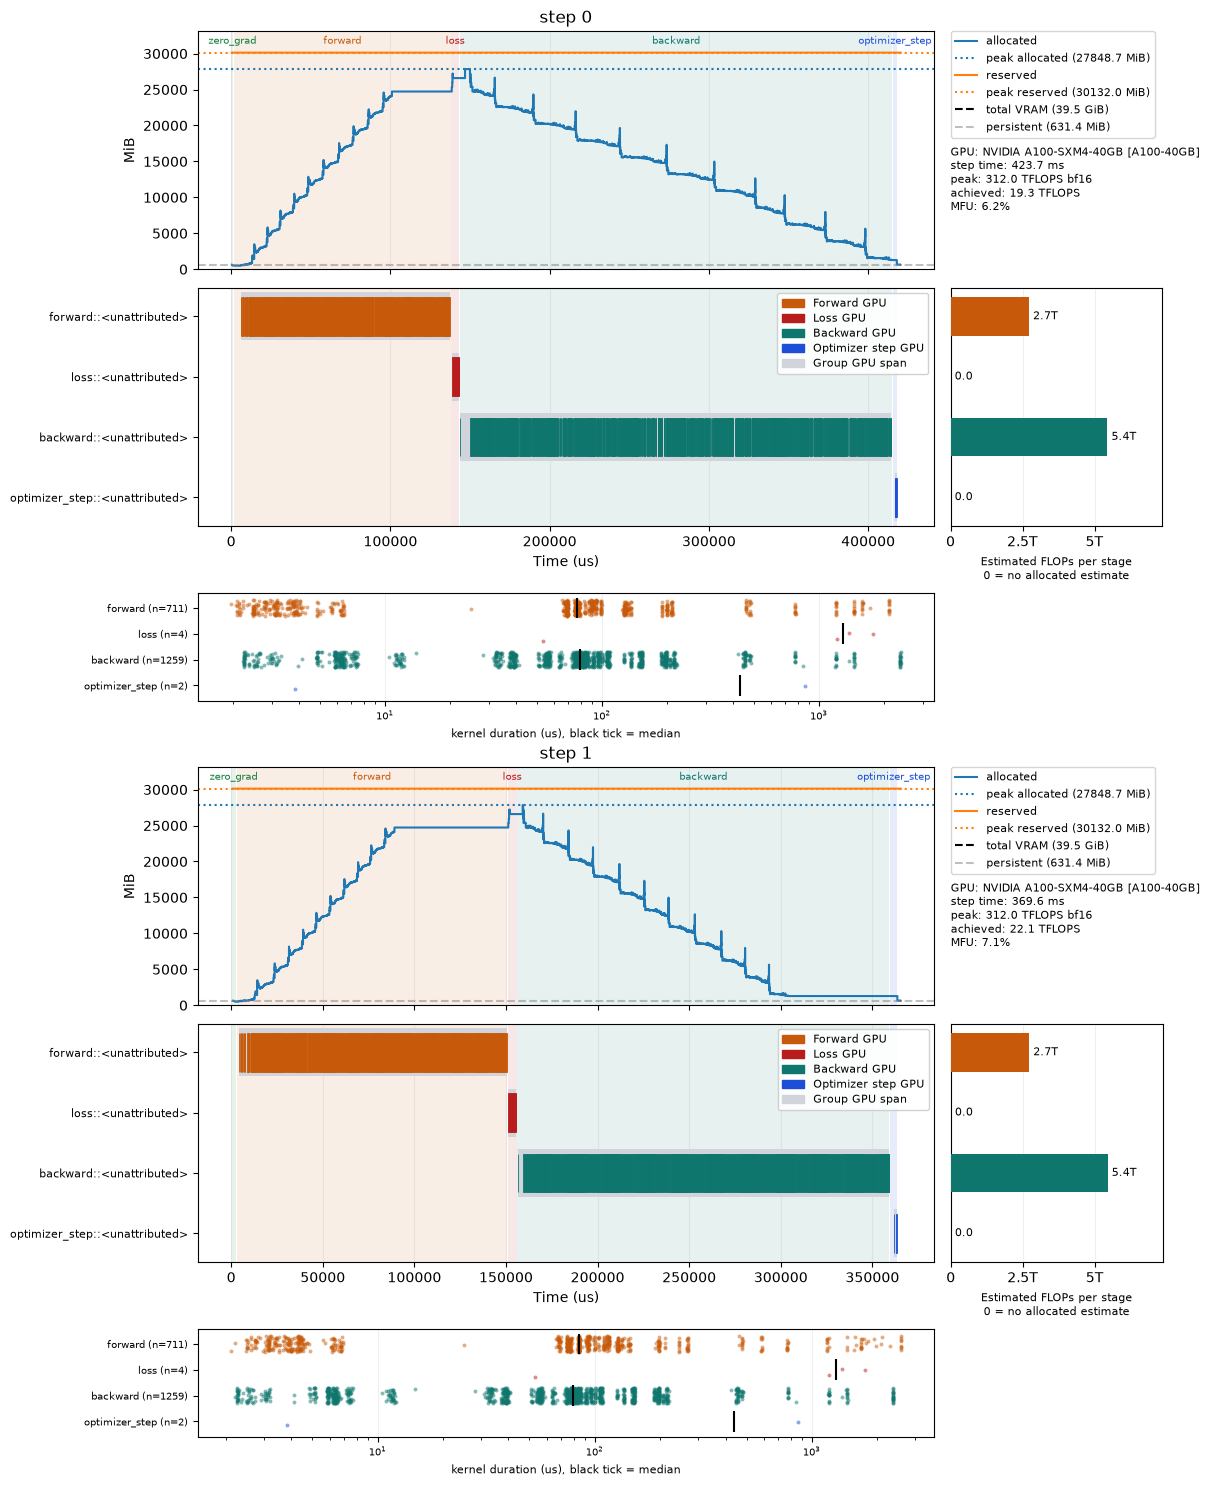

In [19]:
# Every step, stacked; pass steps=[...] to show some of them.
display_steps(report)

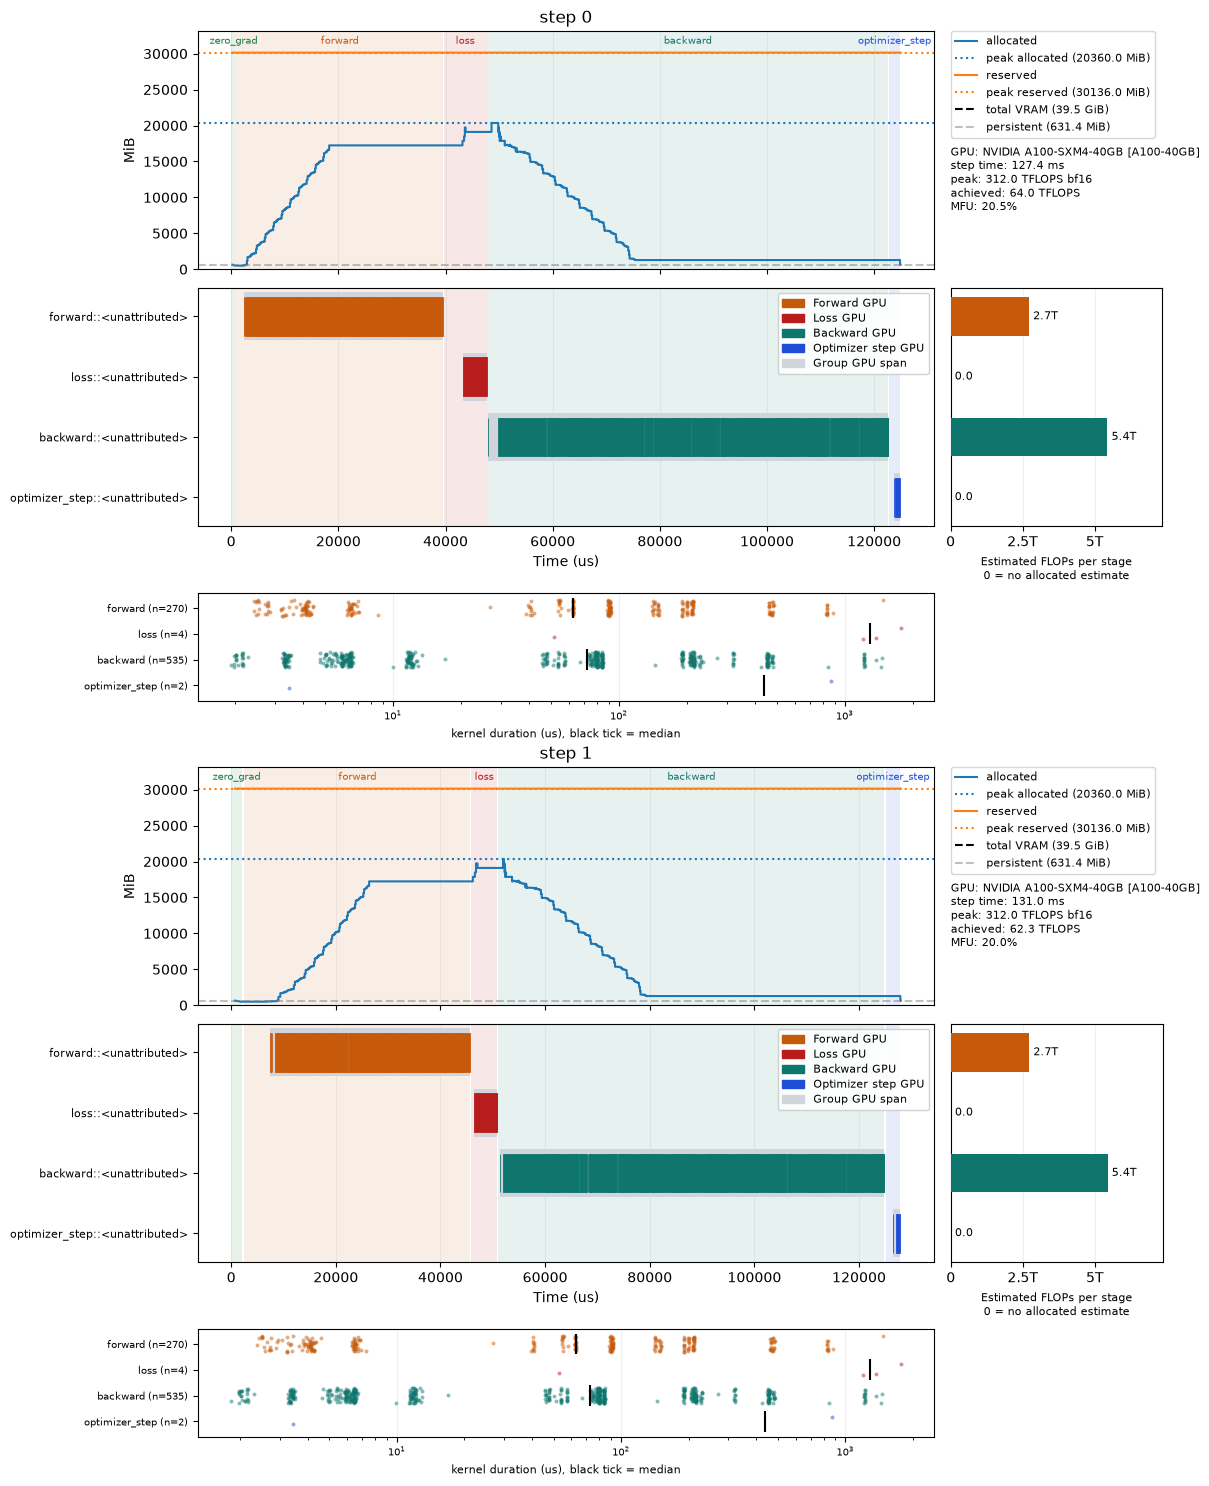

In [ ]:
# Every step, stacked; pass steps=[...] to show some of them. COMPILED
display_steps(report)

## Appendix

## What each id is

`correlation_id` is `FunctionEvent.id`, which `_parse_kineto_results` fills with
`kineto_event.correlation_id()`. What it counts depends on the kind of row:

| Row (`activity_type`) | `correlation_id` | `linked_correlation_id` | `external_id` |
| --- | --- | --- | --- |
| Frontend: op or `record_function` scope (`cpu_op`, `user_annotation`) | PyTorch's own counter | 0 | `correlation_id` |
| Launch call on the CPU (`cuda_runtime`, `cuda_driver`) | CUPTI's counter | the op's `correlation_id` | `linked_correlation_id` |
| GPU work (`kernel`, `gpu_memcpy`, `gpu_memset`) | CUPTI's counter, equal to its launch call's | the op's `correlation_id` | `linked_correlation_id` |
| GPU span of a scope (`gpu_user_annotation`) | its scope's `correlation_id` | 0 | `correlation_id` |
| Profiler overhead (`overhead`) | reuses the `correlation_id` of the op it interrupted | 0 | 0 |

Two counters share the `correlation_id` column, so every lookup by it is restricted to one kind of row:
in one capture `Optimizer.step`'s GPU span and an unrelated launch call were both 1912.
`external_id` holds no value of its own: `KinetoEvent::externalId()` returns
`linked_correlation_id` when there is one, else `correlation_id`.

In [26]:
# One kernel's launch chain, CPU root -> CUDA launch -> kernel. The step and the kernel id are the report's.
step = max(captured["steps"])  # the report's key for it is str(step)
rows = events_to_rows(captured["steps"][step]["events"])
groups, kernels, unattributed_kernels, flop_sources = aggregate_kernels(rows, depth=3)  # the tables behind the report

In [33]:
kernel_id = report["steps"][str(step)]["kernels"]["id"][7]  # Change this to any kernel id in the report.
print("Module:", kernels.loc[kernel_id, "module_fqn"])
display(launch_chain(rows, kernel_id, format=True))  # format=False for the raw rows

Module: <unattributed>


,name,activity_type,device_type,start_us,end_us,launcher_id,correlation_id,linked_correlation_id,flops,input_shapes,input_dtypes
index,,,,,,,,,,,
5,train::forward,user_annotation,DeviceType.CPU,9093.990,55951.159,<NA>,1539,0,0,[],[]
8,Torch-Compiled Region: 0/0,cpu_op,DeviceType.CPU,12515.032,47946.087,5,1541,0,0,[],[]
11,CompiledFunction,cpu_op,DeviceType.CPU,14220.764,47873.680,8,1544,0,0,"[[10000, 512], [64, 512], [512], [512, 512], [...","[float, long int, float, bool, float, float, f..."
12,## Call CompiledFxGraph fpfjyneube2cbp3vb6uehe...,user_annotation,DeviceType.CPU,14542.833,46633.556,11,1545,0,0,[],[]
38,triton_poi_fused__to_copy_add_arange_bmm_index...,cpu_op,DeviceType.CPU,18315.544,18446.896,12,1553,0,0,"[[512, 16], [32768, 512], [512, 16], [64, 16, ...","[float, c10::BFloat16, float, c10::BFloat16, S..."
39,cuLaunchKernel,cuda_driver,DeviceType.CPU,18409.810,18441.828,38,8817,1553,0,[],[]
40,triton_poi_fused__to_copy_add_arange_bmm_index...,kernel,DeviceType.CUDA,18424.208,18482.738,39,8817,1553,0,[],[]


In [39]:
kernels.loc[16]

correlation_id                                                           8738
node_id                                                                    -1
name                        triton_red_fused__to_copy_add_div_index_mean_m...
overload_name                                                                
trace_name                  triton_red_fused__to_copy_add_div_index_mean_m...
time_range                  <torch.autograd.profiler_util.Interval object ...
thread                                                                      1
fwd_thread                                                                  0
count                                                                       1
input_shapes                                                               []
concrete_inputs                                                            []
kwinputs                                                                   {}
stack                                                           

In [44]:
rows.loc[20]

correlation_id                                                           1548
node_id                                                                    -1
name                                                                 aten::mm
overload_name                                                                
trace_name                                                           aten::mm
time_range                  <torch.autograd.profiler_util.Interval object ...
thread                                                                      1
fwd_thread                                                                  0
count                                                                       1
input_shapes                         [[32768, 512], [512, 512], [32768, 512]]
concrete_inputs                                            [None, None, None]
kwinputs                                                                   {}
stack                                                           

In [43]:
display(launch_chain(rows, 20, format=True))  # format=False for the raw rows

,name,activity_type,device_type,start_us,end_us,launcher_id,correlation_id,linked_correlation_id,flops,input_shapes,input_dtypes
index,,,,,,,,,,,
5,train::forward,user_annotation,DeviceType.CPU,9093.990,55951.159,<NA>,1539,0,0,[],[]
8,Torch-Compiled Region: 0/0,cpu_op,DeviceType.CPU,12515.032,47946.087,5,1541,0,0,[],[]
11,CompiledFunction,cpu_op,DeviceType.CPU,14220.764,47873.680,8,1544,0,0,"[[10000, 512], [64, 512], [512], [512, 512], [...","[float, long int, float, bool, float, float, f..."
12,## Call CompiledFxGraph fpfjyneube2cbp3vb6uehe...,user_annotation,DeviceType.CPU,14542.833,46633.556,11,1545,0,0,[],[]
20,aten::mm,cpu_op,DeviceType.CPU,16633.060,17561.638,12,1548,0,17179869184,"[[32768, 512], [512, 512], [32768, 512]]","[c10::BFloat16, c10::BFloat16, c10::BFloat16]"


In [34]:
groups

,,kernel_ids,owner_stage_ids,kernel_count,estimated_flops,flop_source_ids,gpu_start_us,gpu_end_us,gpu_span_us,gpu_time_us
phase,module_fqn,,,,,,,,,
forward,<unattributed>,"[16, 19, 23, 26, 30, 33, 37, 40, 43, 47, 50, 6...",[],270,2.719251e+12,"[20, 27, 34, 44, 53, 59, 68, 77, 89, 100, 107,...",16021.737,55758.473,39736.736,36463.256
loss,<unattributed>,"[918, 937, 938, 939]",[],4,0.000000e+00,[],57170.291,61555.189,4384.898,4381.762
backward,<unattributed>,"[947, 955, 982, 986, 995, 1014, 1023, 1048, 10...",[],535,5.438502e+12,"[991, 996, 1016, 1020, 1028, 1031, 1036, 1039,...",62422.191,138520.011,76097.820,73872.645
optimizer_step,<unattributed>,"[3240, 3243]",[],2,0.000000e+00,[],141051.670,142750.569,1698.899,878.011


In [67]:
rows.loc[groups.loc['forward','<unattributed>'].flop_source_ids][['name','flops']].groupby('name').sum().sum()

flops    2719251169280
dtype: int64

## Shortening the training step

Each variant trains the same model from the same seed under bf16 autocast, and is timed over 100 steps after warmup with CUDA events, with no profiler or memory tracing. Options stack left to right:

- `original`: `models.transformer` as written, with `torch.optim.AdamW`.
- `compile`: `torch.compile` on the model and its cross-entropy loss together.
- `fast`: `FastLM` in [fast_transformer.py](fast_transformer.py), the same math rearranged: Q/K/V and W1/W3 as one matmul each, flash attention through `scaled_dot_product_attention`, fused RMSNorm, and fused AdamW. `fast_model` at the top declares it, for `capture`.
- `graph`: the whole step (forward, backward, optimizer) captured once as a CUDA graph and replayed, so the CPU launches nothing per step.

**Where the time goes on an L4.** About 3.5 ms of a step is matmuls, which reach ~59 TFLOPS; Triton GEMMs autotuned against cuBLAS do no better, so that is the card's practical ceiling. The rest is fused elementwise work (RMSNorm, SwiGLU, RoPE, cross entropy), flash attention and the optimizer. CUDA graphs barely help because the step is GPU-bound, not launch-bound.


In [ ]:
gpu_specs

## TODO: achieved throughput against the GPU's peak

`gpu_specs` above holds each GPU's datasheet peaks, keyed by the name `capture` is called with. Still to do:

- `capture` returns `torch.cuda.get_device_name()`, and the notebook maps it back to a `gpu_specs` row (`gpu` is the Modal name, the device name is the vendor's).
- Add the ceilings measured on each GPU next to the datasheet ones, since a 72 W L4 runs well below its datasheet: about 59 TFLOPS on the largest bf16 matmul and about 240 GB/s streaming through memory in an optimizer-style kernel.
- Report each stage's achieved FLOP/s from `step_flops` and the stage's wall-clock time, as a fraction of `gpu_specs`' peak for the precision it ran in.
- Don't use `torch._inductor.analysis.device_info`: its L4 entry reports the sparse 242 TFLOPS as dense and the H100's 3350 GB/s as bandwidth.
